# Giornata 2 — Fit e diagnostica
## Fase preliminare
Analizziamo con un fit pesato i dati simulati nella giornata 1. In questa fase definiamo il modello
$$ f(x; B, I_0, \alpha, \delta) = B + I_0 \, E(x) \, C(x) $$
e le funzioni di supporto per fit, correlazione e diagnostica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.optimize import curve_fit

# stile comune del corso
# colori: AZZURRO dati e simulazioni, ROSSO modello e fit, GRIGIO riferimenti, ARANCIONE confronti, ORO mediana
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)


def E(x, alpha):
    return np.sinc(alpha * x / np.pi) ** 2


def C(x, delta):
    return np.cos(delta * x) ** 2


def f(x, B, I0, alpha, delta):
    return B + I0 * E(x, alpha) * C(x, delta)


def fit(modello, x, y, sigma_y, p0, lower, upper):
    return curve_fit(
        modello, x, y,
        p0=p0,
        sigma=sigma_y,
        absolute_sigma=True,
        bounds=(lower, upper),
        maxfev=100000,
    )


def riporta(nome, valore, u, unita=""):
    # valore e incertezza con 2 cifre significative sull'incertezza
    d = max(0, 1 - int(np.floor(np.log10(u))))
    return f"{nome} = {valore:.{d}f} ± {u:.{d}f} {unita}".strip()


def correlazione(C):
    u = np.sqrt(np.diag(C))
    return C / np.outer(u, u)


def mappa_correlazione(corr, etichette):
    fig, ax = plt.subplots(figsize=(5.5, 4.6))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(etichette)), etichette)
    ax.set_yticks(range(len(etichette)), etichette)
    ax.set_title("Matrice di correlazione")
    fig.colorbar(im, label="correlazione")
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center")
    plt.show()


def diagnostica(modello, popt, x, y, sigma_y, titolo):
    # pull, chi2 e p-value, con figura dati + fit sopra e pull sotto
    pull = (y - modello(x, *popt)) / sigma_y
    chi2 = np.sum(pull**2)
    dof = len(x) - len(popt)
    p_value = stats.chi2.sf(chi2, dof)
    print(f"chi2 = {chi2:.2f}, dof = {dof}, chi2_rid = {chi2 / dof:.2f}, p-value = {p_value:.4f}")

    fig, ax = plt.subplots(2, 1, figsize=(8.2, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    ax[0].errorbar(x, y, sigma_y, fmt=".", color=AZZURRO, alpha=0.5, label="dati")
    ax[0].plot(x, modello(x, *popt), color=ROSSO, label="fit")
    ax[0].set(ylabel="conteggi", title=titolo)
    ax[0].legend()
    ax[1].plot(x, pull, ".", color=AZZURRO)
    ax[1].axhline(0, color=GRIGIO, ls="--")
    for livello in [-2, -1, 1, 2]:
        ax[1].axhline(livello, color=GRIGIO, ls=":")
    ax[1].set(xlabel="posizione (mm)", ylabel="pull")
    plt.tight_layout()
    plt.show()
    return chi2, dof, p_value

## Attività 1
Leggiamo `dati.csv` senza modificare l'ordine delle righe e verifichiamo che gli array abbiano la stessa lunghezza, contengano valori finiti, abbiano incertezze positive e posizioni ordinate. Rappresentiamo poi i dati con barre di errore (per ora senza fit).

numero di punti = 161
array della stessa lunghezza: True
valori finiti: True
incertezze positive: True
posizioni ordinate: True
intervallo di x = [-5.0, 5.0] mm
intervallo di y = [13, 451] conteggi
intervallo di sigma_y = [3.6, 21.2] conteggi


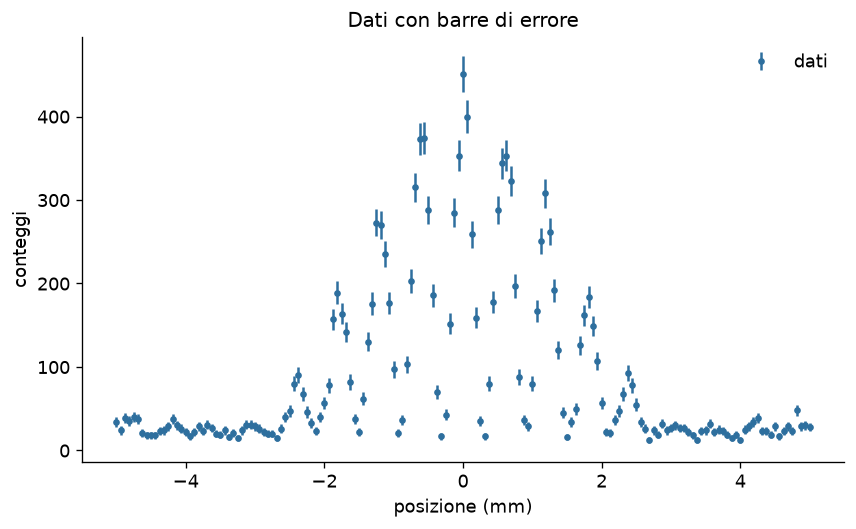

In [2]:
dati = np.genfromtxt("dati.csv", delimiter=",", names=True)
x = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

print(f"numero di punti = {len(x)}")
print(f"array della stessa lunghezza: {len(x) == len(y) == len(sigma_y)}")
print(f"valori finiti: {np.all(np.isfinite([x, y, sigma_y]))}")
print(f"incertezze positive: {np.all(sigma_y > 0)}")
print(f"posizioni ordinate: {np.all(np.diff(x) > 0)}")
print(f"intervallo di x = [{x.min()}, {x.max()}] mm")
print(f"intervallo di y = [{y.min():.0f}, {y.max():.0f}] conteggi")
print(f"intervallo di sigma_y = [{sigma_y.min():.1f}, {sigma_y.max():.1f}] conteggi")

fig, ax = plt.subplots()
ax.errorbar(x, y, sigma_y, fmt=".", color=AZZURRO, label="dati")
ax.set(xlabel="posizione (mm)", ylabel="conteggi", title="Dati con barre di errore")
ax.legend()
plt.show()

## Attività 2
Stimiamo i parametri iniziali, coerenti con i dati e dentro i bounds:
$$ B^{(0)} \simeq \mathrm{mediana}(y_\mathrm{esterni}), \qquad I_0^{(0)} \simeq \max(y) - B^{(0)} $$
con $y_\mathrm{esterni}$ i punti con $|x| > 2.5$ mm. $\alpha^{(0)}$ e $\delta^{(0)}$ vanno scelti in modo coerente con il grafico: il primo minimo dell'inviluppo è in $x = \pi/\alpha$ e la distanza tra due frange è $\pi/\delta$. I bounds sono positivi e abbastanza ampi da non forzare la soluzione sul bordo.

In [3]:
B_0 = np.median(y[np.abs(x) > 2.5])
I0_0 = np.max(y) - B_0
alpha_0 = 1
delta_0 = 5

p0 = np.array([B_0, I0_0, alpha_0, delta_0])
lower = np.array([0.0, 0.0, 0.10, 1.0])
upper = np.array([np.inf, np.inf, 3.0, 12.0])

tab_p0 = pd.DataFrame({"p0": p0, "lower": lower, "upper": upper}, index=["B", "I0", "alpha", "delta"])
print(tab_p0)
print(f"p0 dentro i bounds: {np.all((p0 >= lower) & (p0 <= upper))}")

          p0  lower  upper
B       24.0    0.0    inf
I0     427.0    0.0    inf
alpha    1.0    0.1    3.0
delta    5.0    1.0   12.0
p0 dentro i bounds: True


## Attività 3
Eseguiamo il fit pesato a partire dai parametri appena definiti, ottenendo i parametri ottimali e la matrice di covarianza. Calcoliamo le incertezze di ogni parametro
$$ u(\theta_j) = \sqrt{(C_\theta)_{jj}} $$
e controlliamo che nessun parametro sia vicino a un bound. Infine calcoliamo la matrice di correlazione e la rappresentiamo con una mappa di colore.
$$ \rho_{ij} = \frac{(C_\theta)_{ij}}{\sqrt{(C_\theta)_{ii} (C_\theta)_{jj}}} $$

B = 19.03 ± 0.50 conteggi
I0 = 401.3 ± 5.0 conteggi
alpha = 0.9048 ± 0.0069 mm^-1
delta = 5.1974 ± 0.0058 mm^-1
parametri vicini a un bound: False


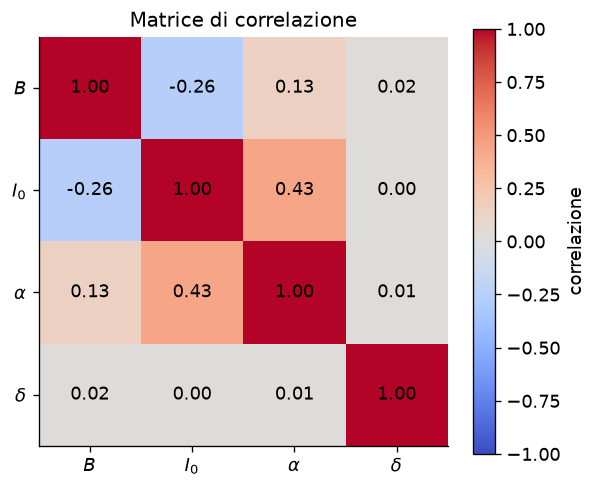

In [4]:
popt, pcov = fit(f, x, y, sigma_y, p0, lower, upper)
u_popt = np.sqrt(np.diag(pcov))

nomi = ["B", "I0", "alpha", "delta"]
unita = ["conteggi", "conteggi", "mm^-1", "mm^-1"]
for nome, valore, u, un in zip(nomi, popt, u_popt, unita):
    print(riporta(nome, valore, u, un))

vicino = (np.abs(popt - lower) < u_popt) | (np.abs(upper - popt) < u_popt)
print(f"parametri vicini a un bound: {vicino.any()}")

corr = correlazione(pcov)
mappa_correlazione(corr, [r"$B$", r"$I_0$", r"$\alpha$", r"$\delta$"])

## Attività 4
Calcoliamo residui, pull, $\chi^2$, gradi di libertà e p-value:
$$ r_i = y_i - f(x_i; \hat\theta) \qquad \rho_i = \frac{r_i}{\sigma_{y_i}} \qquad \chi^2 = \sum_i \rho_i^2 \qquad \nu = N - 4 \qquad \chi^2_\mathrm{rid} = \frac{\chi^2}{\nu} $$
Mostriamo poi una figura con i dati e il fit sopra e i pull sotto, con i livelli $0$, $\pm 1$ e $\pm 2$.

chi2 = 169.41, dof = 157, chi2_rid = 1.08, p-value = 0.2358


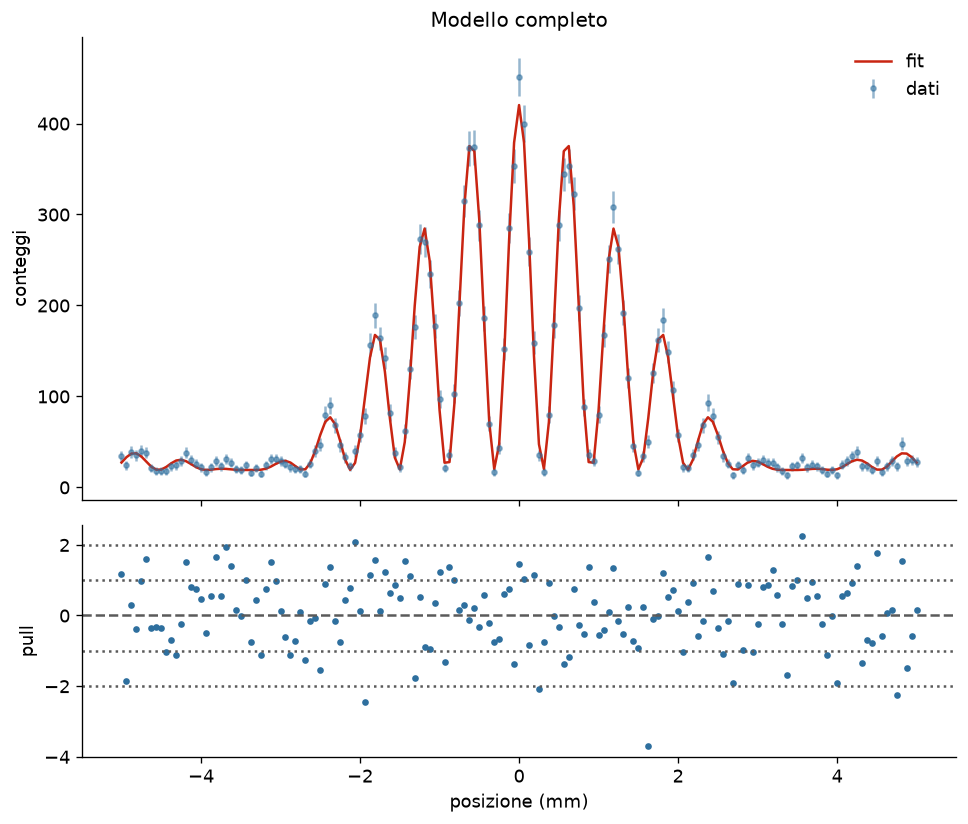

In [5]:
chi2, dof, p_value = diagnostica(f, popt, x, y, sigma_y, "Modello completo")

## Attività 5
Ripetiamo il fit con il modello privo dell'inviluppo, con gli stessi dati e le stesse incertezze:
$$ f_\mathrm{rid}(x) = B + I_0 \cos^2(\delta x) $$

chi2 = 7347.65, dof = 158, chi2_rid = 46.50, p-value = 0.0000


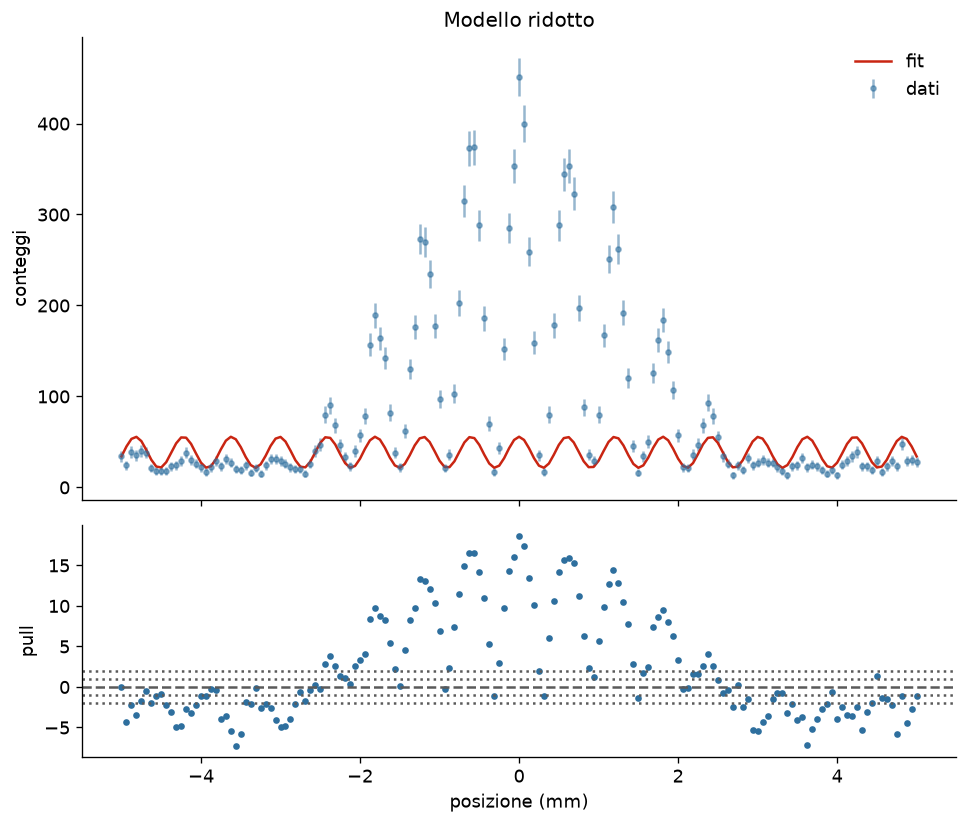

                     Modello completo  Modello ridotto
numero di parametri                 4                3
chi2                            169.4             7348
gradi di libertà                  157              158
chi2/dof                        1.079             46.5
p-value                        0.2358                0


In [6]:
def f_rid(x, B, I0, delta):
    return B + I0 * C(x, delta)


p0_rid = [B_0, I0_0, delta_0]
lower_rid = [0.0, 0.0, 1.0]
upper_rid = [np.inf, np.inf, 12.0]
popt_rid, _ = fit(f_rid, x, y, sigma_y, p0_rid, lower_rid, upper_rid)

chi2_rid, dof_rid, p_value_rid = diagnostica(f_rid, popt_rid, x, y, sigma_y, "Modello ridotto")

tab5 = pd.DataFrame(
    {
        "Modello completo": [len(popt), chi2, dof, chi2 / dof, p_value],
        "Modello ridotto": [len(popt_rid), chi2_rid, dof_rid, chi2_rid / dof_rid, p_value_rid],
    },
    index=["numero di parametri", "chi2", "gradi di libertà", "chi2/dof", "p-value"],
)
print(tab5.to_string(float_format="{:.4g}".format))